# WMATA_Data_Inspection

Project:How do weather conditions affect WMATA Metrorail service?

This notebook checks the data we collected on October 23–24, 2026. The goal is data quality inspection, not cleaning or building the final train-arrival dataset. The original raw files are not changed. 

The goal of this notebook is finding problems of our collected dataset.

## 1. Import libraries and set file path

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
import gzip
from pathlib import Path

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW = ROOT / "data" / "raw"

print("Data folder:", RAW)
print("Folder exists:", RAW.exists())

Data folder: c:\Users\ab966\602DS\data\raw
Folder exists: True


## 2. Load the CSV files

The pilot has two CSV files (October 23 and 24) for each source. Combine both days for the inspection.

In [7]:
# WMATA Predictions
pred1 = pd.read_csv(RAW / "wmata_predictions_2026-10-23.csv")
pred2 = pd.read_csv(RAW / "wmata_predictions_2026-10-24.csv")
predictions = pd.concat([pred1, pred2])

# Weather
weather1 = pd.read_csv(RAW / "weather_2026-10-23.csv")
weather2 = pd.read_csv(RAW / "weather_2026-10-24.csv")
weather = pd.concat([weather1, weather2])

# Incidents
inc1 = pd.read_csv(RAW / "wmata_incidents_2026-10-23.csv")
inc2 = pd.read_csv(RAW / "wmata_incidents_2026-10-24.csv")
incidents = pd.concat([inc1, inc2])

# Train positions
pos1 = pd.read_csv(RAW / "train_positions_2026-10-23.csv")
pos2 = pd.read_csv(RAW / "train_positions_2026-10-24.csv")
positions = pd.concat([pos1, pos2])

print("Predictions:", predictions.shape)
print("Weather:", weather.shape)
print("Incidents:", incidents.shape)
print("Train Positions:", positions.shape)

Predictions: (752791, 10)
Weather: (97, 12)
Incidents: (63, 11)
Train Positions: (134108, 10)


## 3. Look at the columns and example rows

In [8]:
print("Predictions columns:", predictions.columns.tolist())
print("Weather columns:", weather.columns.tolist())
print("Incidents columns:", incidents.columns.tolist())
print("Positions columns:", positions.columns.tolist())

display(predictions.head(3))
display(weather.head(3))
display(incidents.head(3))
display(positions.head(3))

Predictions columns: ['Car', 'Destination', 'DestinationCode', 'DestinationName', 'Group', 'Line', 'LocationCode', 'LocationName', 'Min', 'snapshot_ts']
Weather columns: ['time', 'interval', 'temperature_2m', 'precipitation', 'rain', 'snowfall', 'wind_speed_10m', 'wind_gusts_10m', 'weather_code', 'snapshot_ts', 'latitude', 'longitude']
Incidents columns: ['IncidentID', 'Description', 'StartLocationFullName', 'EndLocationFullName', 'PassengerDelay', 'DelaySeverity', 'IncidentType', 'EmergencyText', 'LinesAffected', 'DateUpdated', 'snapshot_ts']
Positions columns: ['TrainId', 'TrainNumber', 'CarCount', 'DirectionNum', 'CircuitId', 'DestinationStationCode', 'LineCode', 'SecondsAtLocation', 'ServiceType', 'snapshot_ts']


,Car,Destination,DestinationCode,DestinationName,Group,Line,LocationCode,LocationName,Min,snapshot_ts
0,8,Shady Grove,NaN,Shady Grove,2,RD,A01,Metro Center,BRD,2026-10-23 18:25:40.366110+00:00
1,8,Shady Grv,NaN,Shady Grv,2,RD,A03,Dupont Circle,BRD,2026-10-23 18:25:40.366110+00:00
2,8,Glenmont,B11,Glenmont,1,RD,A06,Van Ness-UDC,BRD,2026-10-23 18:25:40.366110+00:00


,time,interval,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,wind_gusts_10m,weather_code,snapshot_ts,latitude,longitude
0,2026-10-23T18:15,900,16.9,0.0,0.0,0.0,13.4,17.3,0,2026-10-23 18:25:42.173700+00:00,38.8983,-77.0281
1,2026-10-23T18:30,900,17.0,0.0,0.0,0.0,13.0,16.2,0,2026-10-23 18:30:51.718981+00:00,38.8983,-77.0281
2,2026-10-23T18:30,900,17.0,0.0,0.0,0.0,12.5,16.2,0,2026-10-23 18:36:55.260717+00:00,38.8983,-77.0281


,IncidentID,Description,StartLocationFullName,EndLocationFullName,PassengerDelay,DelaySeverity,IncidentType,EmergencyText,LinesAffected,DateUpdated,snapshot_ts
0,c7b89fd3-8f33-4952-8e76-6c8fca33c077,Trains are no longer single tracking. Customer...,NaN,NaN,0.0,NaN,Alert,NaN,OR; SV;,2026-10-23T14:15:11,2026-10-23 18:25:41.644890+00:00
1,c7b89fd3-8f33-4952-8e76-6c8fca33c077,Trains are no longer single tracking. Customer...,NaN,NaN,0.0,NaN,Alert,NaN,OR; SV;,2026-10-23T14:15:11,2026-10-23 18:30:49.664588+00:00
2,c7b89fd3-8f33-4952-8e76-6c8fca33c077,Trains are no longer single tracking. Customer...,NaN,NaN,0.0,NaN,Alert,NaN,OR; SV;,2026-10-23T14:15:11,2026-10-23 18:35:50.570655+00:00


,TrainId,TrainNumber,CarCount,DirectionNum,CircuitId,DestinationStationCode,LineCode,SecondsAtLocation,ServiceType,snapshot_ts
0,115,770,6,2,3517,NaN,NaN,31337,NoPassengers,2026-10-23 18:25:40.958308+00:00
1,189,0,6,1,2580,NaN,NaN,15346,Unknown,2026-10-23 18:25:40.958308+00:00
2,208,0,6,1,2494,NaN,NaN,15932,Unknown,2026-10-23 18:25:40.958308+00:00


## 4. Check missing values

In [9]:
print("Predictions missing values (%):")
print((predictions.isnull().mean() * 100).round(2))

print("\nWeather missing values (%):")
print((weather.isnull().mean() * 100).round(2))

print("\nIncidents missing values (%):")
print((incidents.isnull().mean() * 100).round(2))

print("\nTrain Positions missing values (%):")
print((positions.isnull().mean() * 100).round(2))

Predictions missing values (%):
Car                 3.23
Destination         0.00
DestinationCode    49.20
DestinationName     0.00
Group               0.00
Line                0.00
LocationCode        0.00
LocationName        0.00
Min                 0.19
snapshot_ts         0.00
dtype: float64

Weather missing values (%):
time              0.0
interval          0.0
temperature_2m    0.0
precipitation     0.0
rain              0.0
snowfall          0.0
wind_speed_10m    0.0
wind_gusts_10m    0.0
weather_code      0.0
snapshot_ts       0.0
latitude          0.0
longitude         0.0
dtype: float64

Incidents missing values (%):
IncidentID                 0.0
Description                0.0
StartLocationFullName    100.0
EndLocationFullName      100.0
PassengerDelay             0.0
DelaySeverity            100.0
IncidentType               0.0
EmergencyText            100.0
LinesAffected              0.0
DateUpdated                0.0
snapshot_ts                0.0
dtype: float64

Train P

## 5. Check exact duplicate rows

In [10]:
print("Prediction exact duplicates:", predictions.duplicated().sum())
print("Weather exact duplicates:", weather.duplicated().sum())
print("Incident exact duplicates:", incidents.duplicated().sum())
print("Train position exact duplicates:", positions.duplicated().sum())

Prediction exact duplicates: 252
Weather exact duplicates: 0
Incident exact duplicates: 0
Train position exact duplicates: 114


## 6. Check collection time coverage

In [11]:
predictions["snapshot_ts"] = pd.to_datetime(predictions["snapshot_ts"])
weather["snapshot_ts"] = pd.to_datetime(weather["snapshot_ts"])
incidents["snapshot_ts"] = pd.to_datetime(incidents["snapshot_ts"])
positions["snapshot_ts"] = pd.to_datetime(positions["snapshot_ts"])

print("Predictions:")
print("Start:", predictions["snapshot_ts"].min())
print("End:", predictions["snapshot_ts"].max())
print("Unique snapshots:", predictions["snapshot_ts"].nunique())
print("Duration:", predictions["snapshot_ts"].max() - predictions["snapshot_ts"].min())

print("\nWeather:")
print("Start:", weather["snapshot_ts"].min())
print("End:", weather["snapshot_ts"].max())
print("Unique snapshots:", weather["snapshot_ts"].nunique())

print("\nIncidents:")
print("Start:", incidents["snapshot_ts"].min())
print("End:", incidents["snapshot_ts"].max())
print("Unique snapshots with records:", incidents["snapshot_ts"].nunique())

print("\nTrain Positions:")
print("Start:", positions["snapshot_ts"].min())
print("End:", positions["snapshot_ts"].max())
print("Unique snapshots:", positions["snapshot_ts"].nunique())

Predictions:
Start: 2026-10-23 18:25:40.366110+00:00
End: 2026-10-24 06:35:57.084904+00:00
Unique snapshots: 1406
Duration: 0 days 12:10:16.718794

Weather:
Start: 2026-10-23 18:25:42.173700+00:00
End: 2026-10-24 06:23:08.445909+00:00
Unique snapshots: 97

Incidents:
Start: 2026-10-23 18:25:41.644890+00:00
End: 2026-10-24 04:34:19.542770+00:00
Unique snapshots with records: 63

Train Positions:
Start: 2026-10-23 18:25:40.958308+00:00
End: 2026-10-24 06:35:58.792917+00:00
Unique snapshots: 1406


### Collection gaps

In [12]:
# Check gaps between unique prediction snapshots
snapshot_times = predictions["snapshot_ts"].dropna().drop_duplicates().sort_values()
gaps = snapshot_times.diff().dt.total_seconds()

print("Median gap (seconds):", round(gaps.median(), 1))
print("Largest gap (minutes):", round(gaps.max() / 60, 1))
print("Gaps longer than 2 minutes:", (gaps > 120).sum())

Median gap (seconds): 52.3
Largest gap (minutes): 5.1
Gaps longer than 2 minutes: 1


## 7. WMATA Predictions: stations, lines, and Min

In [15]:
print("Unique stations:", predictions["LocationCode"].nunique())

print("\nRecords by Line:")
print(predictions["Line"].value_counts())

print("\nMissing DestinationCode:", predictions["DestinationCode"].isnull().sum())
print("Missing DestinationCode (%):", round(predictions["DestinationCode"].isnull().mean() * 100, 2))

print("\nMost common Min values:")
print(predictions["Min"].value_counts().head(15))

numeric_min = pd.to_numeric(predictions["Min"], errors="coerce")
print("\nNon-numeric or missing Min:", numeric_min.isnull().sum())
print(predictions.loc[numeric_min.isnull(), "Min"].value_counts())

Unique stations: 102

Records by Line:
Line
RD    203792
SV    155781
GR    119549
OR     95083
BL     91075
YL     84447
No      1834
--      1230
Name: count, dtype: int64

Missing DestinationCode: 370389
Missing DestinationCode (%): 49.2

Most common Min values:
Min
2      45876
BRD    45641
5      44880
3      44331
6      43103
4      42764
7      41012
8      40643
9      38138
1      34957
10     33906
11     31842
12     27331
13     24723
ARR    22464
Name: count, dtype: int64

Non-numeric or missing Min: 70300
Min
BRD    45641
ARR    22464
---      800
Name: count, dtype: int64


## 8. Weather: repeated observation times

In [16]:
print("Weather rows:", len(weather))
print("Unique collection snapshots:", weather["snapshot_ts"].nunique())
print("Unique weather observation times:", weather["time"].nunique())

# Repeated observation time at the same location
weather_repeated = weather.duplicated(subset=["time", "latitude", "longitude"]).sum()
print("Repeated weather observations:", weather_repeated)

print("\nTemperature:")
print(weather["temperature_2m"].describe())

print("\nPrecipitation:")
print(weather["precipitation"].describe())
print("Records with precipitation > 0:", (weather["precipitation"] > 0).sum())
print("Records with rain > 0:", (weather["rain"] > 0).sum())

Weather rows: 97
Unique collection snapshots: 97
Unique weather observation times: 49
Repeated weather observations: 48

Temperature:
count    97.000000
mean     12.088660
std       3.815153
min       6.400000
25%       8.900000
50%      11.500000
75%      16.700000
max      17.400000
Name: temperature_2m, dtype: float64

Precipitation:
count    97.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: precipitation, dtype: float64
Records with precipitation > 0: 0
Records with rain > 0: 0


## 9. Incidents: rows versus unique incidents

In [17]:
print("Incident rows:", len(incidents))
print("Unique IncidentIDs:", incidents["IncidentID"].nunique())
print("Repeated IncidentIDs:", incidents["IncidentID"].duplicated().sum())

print("\nIncident type:")
print(incidents["IncidentType"].value_counts())

print("\nAffected lines:")
print(incidents["LinesAffected"].value_counts())

Incident rows: 63
Unique IncidentIDs: 4
Repeated IncidentIDs: 59

Incident type:
IncidentType
Alert    63
Name: count, dtype: int64

Affected lines:
LinesAffected
OR; SV;    35
SV;        28
Name: count, dtype: int64


## 10. Train Positions

In [18]:
print("Train position rows:", len(positions))
print("Unique TrainIds:", positions["TrainId"].nunique())

print("\nLineCode distribution:")
print(positions["LineCode"].value_counts())

print("\nMissing destination station code (%):")
print(round(positions["DestinationStationCode"].isnull().mean() * 100, 2))

Train position rows: 134108
Unique TrainIds: 259

LineCode distribution:
LineCode
RD    29703
GR    23129
SV    22409
YL    19453
BL    17128
OR    14846
Name: count, dtype: int64

Missing destination station code (%):
5.55


## 11. Static GTFS ZIP

In [ ]:
gtfs_path = Raw / "wmata_gtfs_2026-10-23.zip"

with zipfile.ZipFile(gtfs_path) as z:
    print("Files in Static GTFS:")
    print(z.namelist())

    stops = pd.read_csv(z.open("stops.txt"))
    routes = pd.read_csv(z.open("routes.txt"))
    trips = pd.read_csv(z.open("trips.txt"))
    stop_times = pd.read_csv(z.open("stop_times.txt"))

print("\nStops:", stops.shape)
print("Routes:", routes.shape)
print("Trips:", trips.shape)
print("Stop Times:", stop_times.shape)

display(stops.head(3))
display(routes.head(3))

Files in Static GTFS:
['agency.txt', 'calendar_dates.txt', 'routes.txt', 'shapes.txt', 'stop_times.txt', 'stops.txt', 'trips.txt', 'feed_info.txt', 'levels.txt', 'pathways.txt']

Stops: (2176, 10)
Routes: (6, 10)
Trips: (14228, 9)
Stop Times: (344646, 8)


,stop_id,stop_name,stop_desc,stop_lat,stop_lon,zone_id,location_type,parent_station,wheelchair_boarding,level_id
0,STN_N06,Wiehle-Reston East,NaN,38.947832,-77.340316,91,1,NaN,1,NaN
1,STN_N04,Spring Hill,NaN,38.929212,-77.241891,90,1,NaN,1,NaN
2,STN_N03,Greensboro,NaN,38.921269,-77.234162,89,1,NaN,1,NaN


,route_id,agency_id,route_short_name,route_long_name,route_type,route_url,route_color,as_route,network_id,route_text_color
0,RED,1,R,Red,1,NaN,C80F2D,1,Metrorail,FFFFFF
1,BLUE,1,B,Blue,1,NaN,009CDE,1,Metrorail,FFFFFF
2,GREEN,1,G,Green,1,NaN,00B140,1,Metrorail,FFFFFF


## 12. Static GTFS quality checks

In [20]:
print("Stops missing values:")
print(stops.isnull().sum())
print("\nTrips missing values:")
print(trips.isnull().sum())

print("\nExact duplicate rows:")
print("Stops:", stops.duplicated().sum())
print("Routes:", routes.duplicated().sum())
print("Trips:", trips.duplicated().sum())
print("Stop Times:", stop_times.duplicated().sum())

print("\nUnique stop IDs:", stops["stop_id"].nunique())
print("Unique routes:", routes["route_id"].nunique())
print("Unique trips:", trips["trip_id"].nunique())

Stops missing values:
stop_id                  0
stop_name                0
stop_desc               98
stop_lat                 0
stop_lon                 0
zone_id                  0
location_type            0
parent_station          98
wheelchair_boarding      0
level_id               308
dtype: int64

Trips missing values:
route_id                 0
service_id               0
trip_id                  0
trip_headsign            0
direction_id             0
block_id             14228
shape_id                 0
scheduled_trip_id        0
train_id                 0
dtype: int64

Exact duplicate rows:
Stops: 0
Routes: 0
Trips: 0
Stop Times: 0

Unique stop IDs: 2176
Unique routes: 6
Unique trips: 14228


## 13. GTFS-Realtime: file count and basic file check

These are compressed .pb.gz files.

In [21]:
rt = RAW / "gtfs_rt"

vehicle_files = sorted(rt.rglob("vehiclepositions_*.pb.gz"))
trip_files = sorted(rt.rglob("tripupdates_*.pb.gz"))
alert_files = sorted(rt.rglob("alerts_*.pb.gz"))

print("Vehicle Positions files:", len(vehicle_files))
print("Trip Updates files:", len(trip_files))
print("Alerts files:", len(alert_files))
print("Total GTFS-RT files:", len(vehicle_files) + len(trip_files) + len(alert_files))

if len(vehicle_files) > 0:
    print("\nFirst vehicle filename:", vehicle_files[0].name)
    print("Last vehicle filename:", vehicle_files[-1].name)

    with gzip.open(vehicle_files[0], "rb") as f:
        data = f.read()
    print("Decompressed sample size (bytes):", len(data))

Vehicle Positions files: 1231
Trip Updates files: 1231
Alerts files: 1231
Total GTFS-RT files: 3693

First vehicle filename: vehiclepositions_20261023T182540Z.pb.gz
Last vehicle filename: vehiclepositions_20261024T063554Z.pb.gz
Decompressed sample size (bytes): 13771


###  GTFS-Realtime entity check


In [22]:
try:
    from google.transit import gtfs_realtime_pb2

    if len(vehicle_files) > 0:
        feed = gtfs_realtime_pb2.FeedMessage()
        with gzip.open(vehicle_files[0], "rb") as f:
            feed.ParseFromString(f.read())

        print("Vehicle entities in sample:", len(feed.entity))
        print("Feed timestamp:", feed.header.timestamp)
except ImportError:
    print("Optional check skipped. Install gtfs-realtime-bindings to decode protobuf data.")

Optional check skipped. Install gtfs-realtime-bindings to decode protobuf data.


## 14. Visualizations

### Figure 1. Missing values in Predictions

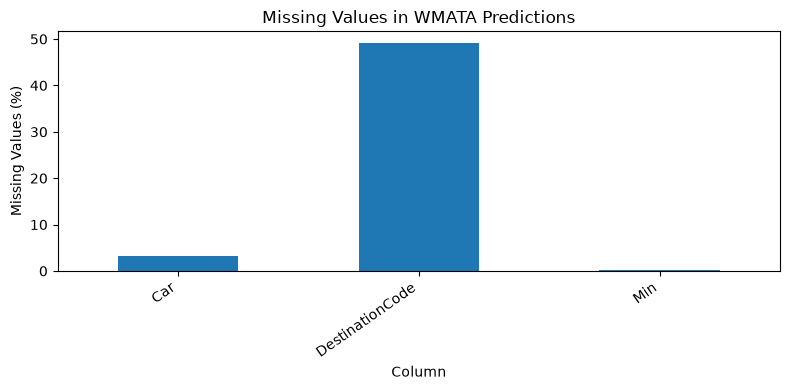

In [23]:
missing = predictions.isnull().mean() * 100
missing = missing[missing > 0]

missing.plot(kind="bar", figsize=(8, 4))
plt.title("Missing Values in WMATA Predictions")
plt.xlabel("Column")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Figure 2. Collection coverage by hour

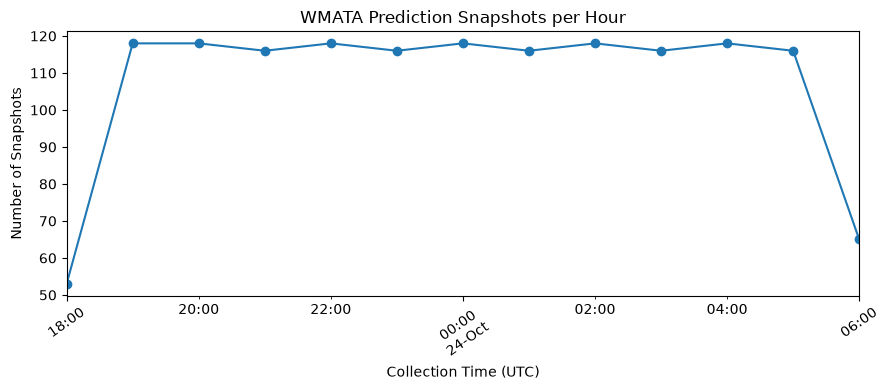

In [24]:
snapshot_times = predictions["snapshot_ts"].dropna().drop_duplicates()
hourly_snapshots = snapshot_times.dt.floor("h").value_counts().sort_index()

hourly_snapshots.plot(kind="line", marker="o", figsize=(9, 4))
plt.title("WMATA Prediction Snapshots per Hour")
plt.xlabel("Collection Time (UTC)")
plt.ylabel("Number of Snapshots")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

### Figure 3. Prediction records by line

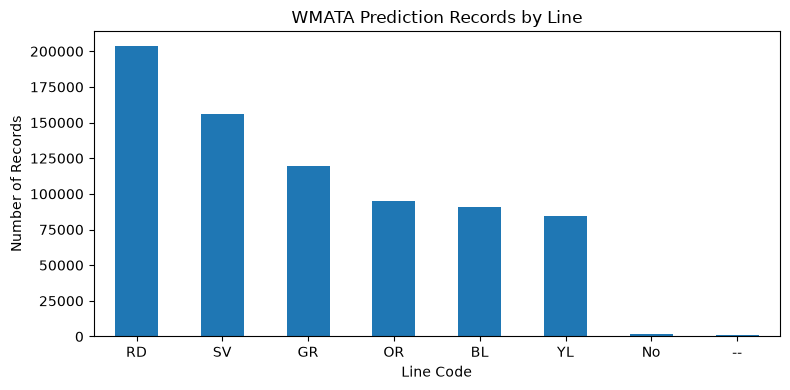

In [25]:
predictions["Line"].value_counts(dropna=False).plot(kind="bar", figsize=(8, 4))
plt.title("WMATA Prediction Records by Line")
plt.xlabel("Line Code")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 15. Pilot Inspection Findings

### 1. Dataset Summary
The pilot data was collected from October 23 to October 24, 2026.
- Collection period: 12 hours and 10 minutes
- WMATA Predictions: 752,791 records and 1,406 unique snapshots
- Train Positions: 134,108 records
- Weather: 97 records
- Incidents: 63 records
- Static GTFS: 2,176 stops, 6 routes, 14,228 trips, and 344,646 stop times
- GTFS-Realtime: 3,693 files, including vehicle positions, trip updates, and alerts

### 2. Data Quality Findings
Missing Values
- About 49.20% of the DestinationCode values were missing in WMATA Predictions.
- The Car column had 3.23% missing values.
- In Train Positions, 5.55% of DestinationStationCode and LineCode values were missing.
- Some incident fields were completely missing, including DelaySeverity and EmergencyText.

Non-Numeric Values
- The Min column contained both numeric and non-numeric values.
- There were 70,300 non-numeric or missing values, including ARR, BRD, and "---".
- These values will need to be handled separately during data cleaning.

Duplicates and Repeated Observations
- Predictions contained 252 exact duplicate rows.
- Train Positions contained 114 exact duplicate rows.
- Weather had 97 records but only 49 unique observation times. This means some weather observations were collected more than once.
- Incidents had 63 records but only 4 unique IncidentIDs. The same incidents appeared in multiple collection snapshots.

Temporal Coverage
- WMATA Predictions contained 1,406 unique collection snapshots over approximately 12 hours.
- The median time between snapshots was 52.3 seconds.
- The largest gap was approximately 5.1 minutes, with one gap longer than 2 minutes.
- This shows that automated collection generally worked, but there was still a small interruption.

Other Findings
- The Line column included values such as "No" and "--" in addition to the six Metro lines.
- No precipitation or rain was recorded during the pilot.
- Static GTFS files were successfully loaded and inspected.
- GTFS-Realtime files were counted, and a sample file was successfully decompressed. However, the internal Protobuf data was not fully inspected.

### 3. Improvements Made

The initial data collection code collected data for a short period, which limited our temporal coverage.

The updated collection system introduced automated repeated collection. As a result, we were able to collect  12 hours of WMATA data.
We also expanded our data sources by collecting Train Positions and GTFS-Realtime data.
These changes improved the collection process and provided more data for checking coverage and data quality.
Our ultimate goal is collecting 7days data by using cloud to get enough data to be analyzed

### 4. Remaining Issues and Next Steps

- Decide how to handle missing DestinationCode values.
- Separate numeric Min values from status values such as ARR and BRD.
- Handle repeated weather observations before combining datasets.
- Investigate unexpected line codes and missing train position fields.
- Check station codes and timestamps across WMATA Predictions, GTFS, and weather data.
- Collect data under different weather conditions, especially rainy days.
- Investigate how to identify actual train arrival events from the collected data.

The pilot showed that our data collection process is feasible. However, several data quality issues still need to be addressed before creating the final dataset.

### 5. AI Usage Disclosure

I used OpenAI Codex for help with Python syntax. I also used AI assistance to inspect the GTFS-Realtime Protobuf (.pb.gz) files and the Static GTFS ZIP file because I was not familiar with how to read and inspect these file formats.